# 5 — Neural Network Models

**Question.** Does the wording of a company's Item 7 (management's discussion) predict its share-price volatility over the next 12 months, beyond what last year's volatility already tells us?
## 5.1 - Data and Requirements

In [2]:
import gzip
import json
import pickle
import sys
import tarfile
import time
import urllib.request
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.linear_model import Ridge
import torch
from torch import nn

ROOT = Path("..")                              # this notebook lives in a personal folder, so the repo root is one level up
PROCESSED = ROOT / "data" / "processed"
OUTPUT = ROOT / "data" / "output"
kogan_dir = ROOT / "data" / "raw" / "kogan"
edgar_dir = PROCESSED / "edgar_matched"
KOGAN_URL = "https://www.cs.cmu.edu/~ark/10K/data/"
BOW_DIR = PROCESSED / "bow"                    # word counts for every report, rebuilt if deleted
BOW_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "Alex"))         # scoring.py: the same file 02-Linear-models imports (it lives in Alex's folder)
import scoring

# --- split: not set here. scoring.masks(df, test_year, window) gives the training and test reports, as in 02 -------
MAIN_WINDOW = "paper"                          # the window used for the single-window views (words, cost, scatter)

# --- features ------------------------------------------------------------------------------------
N_WORDS = 5000                                 # vocabulary size
MIN_DF = 50                                    # a word must appear in at least 50 training reports
TOKEN = r"(?u)\b[a-z]{2,}\b"                   # lower-case words of 2+ letters (numbers dropped, as Kogan's '#' tokens are)

# --- network -------------------------------------------------------------------------------------
HIDDEN = 64
DROPOUT = 0.3
LR = 1e-3
WEIGHT_DECAY = 1e-2
BATCH = 256
MAX_EPOCHS = 40
PATIENCE = 5                                   # stop if validation error has not improved for 5 epochs
SEEDS = [0, 1, 2]
NET_VARIANTS = {False: "words only", True: "words + last year"}

VERY_LOW = -5.0                                # takeover-type reports, as in 04-Volatility-Checking

## 5.2 Reports and the split

Every report has `logvol_before` (12 months before filing) and `logvol_after` (12 months after), both from Kogan. We predict `logvol_after`. The reports, their order and their labels come from `data.pkl` through `scoring.frame` the Item 7 texts are then found by report key.

The split is by **filing year**, not random: a random split would let the model learn a year's market conditions from other reports of the same year. For each test year and window, `scoring.masks` gives the training reports and the test reports. The last training year is held out of the fit and used only to choose the ridge penalty and to stop the network. The table below lists what that means in years; the cell after it checks the windows against the shared `data/output/splits.csv`.

In [3]:
with open(PROCESSED / "data.pkl", "rb") as f:          
    d = pickle.load(f)
df = scoring.frame(d)
y = df["logvol_after"].to_numpy()
prev = df["logvol_before"].to_numpy()
year_arr = df["year"].to_numpy()
print(f"{len(df):,} reports, {df.year.min()}-{df.year.max()}")

def as_mask(m):
    m = np.asarray(m)
    if m.dtype == bool:
        return m
    out = np.zeros(len(df), dtype=bool)
    out[m] = True
    return out

# --- Item 7 source for every report in df ---------------------------------------------------------
meta = pd.read_csv(PROCESSED / "dataset.csv", parse_dates=["date"]).drop(columns="item7_source", errors="ignore")
assert meta["key"].is_unique, "key must identify one report"
src_file = PROCESSED / "item7_source.csv"
USE_EDGAR = src_file.exists() and edgar_dir.exists() and any(edgar_dir.glob("*.jsonl.gz"))
TEXT_TAG = "edgar" if USE_EDGAR else "kogan"
if USE_EDGAR:
    meta = meta.merge(pd.read_csv(src_file)[["key", "item7_source"]], on="key", how="inner")
    assert not meta.duplicated(["cik", "year"]).any(), "company + year must identify one report"
else:
    meta["item7_source"] = "kogan"

# data: one row per report of df, in df order, with what the text loader needs (cik, year, key, item7_source)
data = df[["key"]].merge(meta, on="key", how="left", validate="one_to_one")
missing = data["item7_source"].isna()
assert not missing.any(), f"{int(missing.sum())} reports in data.pkl have no Item 7 source in dataset.csv / item7_source.csv"
assert (data["year"].to_numpy() == year_arr).all(), "filing years differ between data.pkl and dataset.csv"
assert np.allclose(data["logvol_after"], y) and np.allclose(data["logvol_before"], prev), "labels differ between data.pkl and dataset.csv"
print("Item 7 source:", data["item7_source"].value_counts().to_dict(),
      "(EDGAR rule from 03)" if USE_EDGAR else "(Kogan only: item7_source.csv / edgar_matched not found)")

27,142 reports, 1996-2006
Item 7 source: {'kogan': 27142} (Kogan only: item7_source.csv / edgar_matched not found)


In [4]:
rows = []
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        train, test = (as_mask(m) for m in scoring.masks(df, T, window))
        ty = sorted(set(year_arr[train]))
        rows.append({"window": window, "test_year": T, "train_years": f"{ty[0]}-{ty[-1]}", "validate_year": ty[-1],
                     "train_reports": int(train.sum()), "test_reports": int(test.sum())})
split_table = pd.DataFrame(rows)

shared = pd.read_csv(OUTPUT / "splits.csv")
for r in shared.itertuples():
    train, _ = scoring.masks(df, r.test_year, r.window)
    assert as_mask(train).sum() == r.train_reports
assert set(shared.window) == set(scoring.WINDOWS)
print("the windows match data/output/splits.csv")
split_table

the windows match data/output/splits.csv


,window,test_year,train_years,validate_year,train_reports,test_reports
0,paper,2001,1996-2000,2000,9747,2299
1,paper,2002,1997-2001,2001,10788,2587
2,paper,2003,1998-2002,2002,11399,3217
3,paper,2004,1999-2003,2003,12474,3168
4,paper,2005,2000-2004,2004,13422,3121
5,paper,2006,2001-2005,2005,14392,3003
6,strict,2001,1996-1999,1999,7596,2299
7,strict,2002,1997-2000,2000,8489,2587
8,strict,2003,1998-2001,2001,8812,3217
9,strict,2004,1999-2002,2002,9257,3168


How different are the years? If the market was calm in the test years and wild in the training years, scores on the test years will partly reflect that. `typical vol` below is the annualised volatility of the average log-volatility (a geometric mean); `corr` is how well last year's volatility lines up with next year's, year by year.

In [6]:
def annual(logvol):
    return np.exp(logvol) * np.sqrt(252)

by_year = df.groupby("year").agg(reports=("key", "size"),
                                 typical_vol_before=("logvol_before", lambda v: annual(v.mean())),
                                 typical_vol_after=("logvol_after", lambda v: annual(v.mean())),
                                 corr_before_after=("logvol_before", lambda v: np.corrcoef(v, df.loc[v.index, "logvol_after"])[0, 1]))
by_year.style.format({"typical_vol_before": "{:.0%}", "typical_vol_after": "{:.0%}", "corr_before_after": "{:.2f}"})

,reports,typical_vol_before,typical_vol_after,corr_before_after
year,,,,
1996,1258,52%,51%,0.87
1997,1976,53%,55%,0.83
1998,2142,54%,69%,0.77
1999,2220,67%,72%,0.80
2000,2151,69%,75%,0.80
2001,2299,76%,65%,0.82
2002,2587,64%,62%,0.81
2003,3217,57%,46%,0.83
2004,3168,44%,39%,0.83


## 5.3 Text to word counts

For each report we count how often each word occurs (English stop words removed). Counting is done **once for every report**, over a menu of every word that appears in at least 50 reports in the whole data set. The menu is only a list of possible columns: each training window then picks its own 5,000 columns from its own training reports (most frequent words among those in at least 50 training reports, section 3), so nothing from the test year or later decides what a model sees. A word that passes the 50-report rule in a window's training years also passes it over all years, so the menu never removes a word a window would have chosen.

Raw counts are dominated by report length, so before the network sees them each window rescales them, with the idf fitted on that window's training reports only:

$$x_{ij} \propto \big(1 + \ln c_{ij}\big)\cdot \mathrm{idf}_j,\qquad \mathrm{idf}_j = \ln\frac{1+n}{1+\mathrm{df}_j} + 1,$$

where $c_{ij}$ is the count of word $j$ in report $i$, $n$ the number of training reports and $\mathrm{df}_j$ the number containing word $j$. The log stops a word repeated 200 times counting 200 times as much as one used once, and the idf term down-weights words that appear in almost every report ("company", "year"). Each row is then scaled to length 1, so long and short reports are on the same footing.

Reading all the text takes a while, so the counts are saved to `data/processed/bow/` (tagged with the text source and the report keys) and re-used. The time is saved with them because we need it for the scaling discussion.

In [7]:
def kogan_file(year):
    f = kogan_dir / f"{year}.tok.tgz"
    if not f.exists():
        kogan_dir.mkdir(parents=True, exist_ok=True)
        print("downloading", f.name)
        urllib.request.urlretrieve(KOGAN_URL + f.name, f)
    return f

def load_year_texts(year):
    # Item 7 text for every report of `year` in `data`, in `data` order (EDGAR unless 03 chose Kogan)
    rows = data[data["year"] == year]
    want_edgar = {(int(r.cik), int(r.year)): r.key for r in rows.itertuples() if r.item7_source == "edgar"}
    want_kogan = {r.key for r in rows.itertuples() if r.item7_source == "kogan"}
    texts = {}
    if want_edgar:
        with gzip.open(edgar_dir / f"{year}.jsonl.gz", "rt") as f:
            for line in f:
                rec = json.loads(line)
                key = want_edgar.get((int(rec["cik"]), int(rec["year"])))
                if key is not None:
                    texts[key] = rec["section_7"]
    if want_kogan:
        with tarfile.open(kogan_file(year)) as tar:
            for m in tar:
                if m.isfile():
                    key = Path(m.name).name.split(".")[0]
                    if key in want_kogan:
                        texts[key] = tar.extractfile(m).read().decode("utf-8", "replace")
    missing = set(rows["key"]) - set(texts)
    assert not missing, f"{year}: no text found for {len(missing)} reports, e.g. {sorted(missing)[:2]}"
    return [texts[k] for k in rows["key"]]

keys = df["key"].tolist()
years_sorted = sorted(int(v) for v in np.unique(year_arr))
order = np.concatenate([np.flatnonzero(year_arr == yr) for yr in years_sorted])      # rows of df, in the order the texts are read

cache_npz, cache_json = BOW_DIR / f"candidates_{TEXT_TAG}.npz", BOW_DIR / f"candidates_{TEXT_TAG}.json"
cached = None
if cache_npz.exists() and cache_json.exists():
    cached = json.loads(cache_json.read_text())
    if cached["keys"] != keys:
        cached = None
        print("saved word counts are for a different set of reports: counting again")
if cached is not None:
    X_counts = sp.load_npz(cache_npz).tocsr()
    vocab, timings = cached["vocab"], cached["timings"]
    print("loaded saved word counts")
else:
    def all_texts():
        for yr in years_sorted:
            yield from load_year_texts(yr)
    t0 = time.perf_counter()
    vec = CountVectorizer(min_df=MIN_DF, stop_words="english", token_pattern=TOKEN, dtype=np.int32)
    X_sorted = vec.fit_transform(all_texts()).tocsr()
    X_counts = X_sorted[np.argsort(order)]                       # back to df order
    timings = {"count_seconds": time.perf_counter() - t0, "n_reports": int(X_counts.shape[0])}
    vocab = [str(w) for w in vec.get_feature_names_out()]
    sp.save_npz(cache_npz, X_counts)
    cache_json.write_text(json.dumps({"keys": keys, "vocab": vocab, "timings": timings}))

assert X_counts.shape == (len(df), len(vocab)), "row order must match `df`"
vocab = np.array(vocab)
print("count matrix (reports x candidate words):", X_counts.shape, "| timings:", {k: round(v, 1) for k, v in timings.items()})

loaded saved word counts
count matrix (reports x candidate words): (27142, 15344) | timings: {'count_seconds': 91.2, 'n_reports': 27142}


## 5.4 One fit per test year and window

For each (window, test year) the cell below does everything that depends on the split, in one place, so the word counts for that split are built once and then dropped:

1. **Features.** Choose the vocabulary and the idf from the training reports of the window (`build_features`).
2. **Held-out year.** The last training year is the validation year: models are fitted on the other training years and scored on it. That choice sets the ridge penalty and tells the network when to stop (patience 5, best epoch kept).
3. **Baselines.** All scores are mean squared error (MSE) in log-volatility units.
    - **Train mean:** the same number for every report. Anything worse than this has learned nothing.
    - **Copy last year:** `logvol_after = logvol_before`, the baseline named in `01-Planning.ipynb`.
    - **Line through last year:** `logvol_after = a + b * logvol_before`, fitted on the whole training window with `scoring.fit_line`. This is the baseline every model is scored against.
    - **Ridge on words:** a linear model on the same 5,000 features, which tells us whether a network is needed at all. The penalty is chosen on the validation year, then the model is refitted on the whole window, as in 02. Two versions: words only, and words added on top of the line through last year (ridge fitted to what the line gets wrong).
4. **Network.** Two variants, three seeds each (section 4). The network is fitted on the training years without the validation year and keeps the epoch that is best on it. Unlike the ridge it is **not** refitted on the validation year afterwards, so it sees one year less than the ridge does.

The last two baselines use the same inputs as the network, so the network only earns its place by beating them.

In [8]:
def mse(a, b):
    return float(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

def split_key(train, test):
    return (tuple(sorted(int(v) for v in set(year_arr[as_mask(train)]))), int(year_arr[as_mask(test)][0]))

def build_features(train, test):
    # Vocabulary, idf and the feature rows for one (training window, test year). Chosen on the training reports only.
    tr_idx = np.flatnonzero(train)
    counts_tr = X_counts[tr_idx]
    in_reports = np.asarray((counts_tr > 0).sum(axis=0)).ravel()           # training reports containing each word
    total = np.asarray(counts_tr.sum(axis=0)).ravel()                      # training count of each word
    eligible = np.flatnonzero(in_reports >= MIN_DF)
    cols = np.sort(eligible[np.argsort(-total[eligible], kind="stable")[:N_WORDS]])
    rows = np.flatnonzero(train | test)
    tfidf = TfidfTransformer(sublinear_tf=True).fit(counts_tr[:, cols])    # idf from training reports only
    X = tfidf.transform(X_counts[rows][:, cols]).astype(np.float32).tocsr()
    pos = np.full(len(df), -1, dtype=np.int64)                             # pos[report] = its row in X
    pos[rows] = np.arange(len(rows))
    return X, pos, cols

def make_split(train, test):
    train, test = as_mask(train), as_mask(test)
    assert len(set(year_arr[test])) == 1, "one test year at a time"
    years = sorted(int(v) for v in set(year_arr[train]))
    val_year = years[-1]                                    # last training year: chooses the ridge penalty, stops the network
    tr_idx, te_idx = np.flatnonzero(train), np.flatnonzero(test)
    fit_idx = tr_idx[year_arr[tr_idx] != val_year]
    val_idx = tr_idx[year_arr[tr_idx] == val_year]
    X, pos, cols = build_features(train, test)
    mu, sd = y[fit_idx].mean(), y[fit_idx].std()            # for the network: z = (logvol - mu) / sd, same for before and after
    return SimpleNamespace(train=train, test=test, years=tuple(years), val_year=val_year, test_year=int(year_arr[test][0]),
                           tr_idx=tr_idx, te_idx=te_idx, fit_idx=fit_idx, val_idx=val_idx, X=X, pos=pos, cols=cols, mu=mu, sd=sd,
                           y_z=((y - mu) / sd).astype(np.float32), prev_z=((prev - mu) / sd).astype(np.float32))

ALPHAS = [0.1, 0.3, 1, 3, 10]

def fit_ridge(S, tune_target, final_target):
    # penalty: fit on the training years without the validation year, keep the penalty that scores best on it; then refit on the whole window
    best = None
    for a in ALPHAS:
        m = Ridge(alpha=a).fit(S.X[S.pos[S.fit_idx]], tune_target[S.fit_idx])
        v = mse(tune_target[S.val_idx], m.predict(S.X[S.pos[S.val_idx]]))
        if best is None or v < best[0]:
            best = (v, a)
    return Ridge(alpha=best[1]).fit(S.X[S.pos[S.tr_idx]], final_target[S.tr_idx]), best[1]

## 5.5 The network

We will construct two variants of one small network, so we can see what the words contribute on their own and on top of last year's volatility.

With $z = (\text{logvol} - \mu)/\sigma$ (mean and standard deviation of the fitted training years, same for `before` and `after`) and $\mathbf{x}$ the report's feature vector:

$$\hat z_{\text{after}} \;=\; \underbrace{a\,z_{\text{before}} + b}_{\text{skip: last year}} \;+\; \underbrace{\mathbf{w}_2^{\top}\,\mathrm{ReLU}\!\big(W_1\mathbf{x} + \mathbf{b}_1\big) + b_2}_{\text{words}},\qquad W_1\in\mathbb{R}^{64\times 5000}.$$

- The skip term starts at $a=1,\ b=0$ and the word part starts near zero, so training **starts from "copy last year"** and the words can only help by learning a correction. This also makes the comparison with the baseline fair.
- The text-only variant drops the skip term: the network must get everything from the words.
- Weights are trained to minimise MSE with AdamW (weight decay 0.01), dropout 0.3 on the hidden layer, batches of 256. Training stops when the validation-year MSE has not improved for 5 epochs and the best epoch is kept.
- About 320,000 parameters, against roughly 15,000 training reports in a window: heavy regularisation matters, which is why validation-based stopping is used.
- Each batch is turned into a dense array only when needed, so the full 5,000-wide table never sits in memory densely.

In [9]:
device = "cpu"          # GPU is not needed at this size; see section 8 for what changes at scale

class WordCountNet(nn.Module):
    def __init__(self, n_words, hidden=HIDDEN, dropout=DROPOUT, use_prev=True):
        super().__init__()
        self.use_prev = use_prev
        self.text = nn.Sequential(nn.Linear(n_words, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1))
        if use_prev:
            self.skip = nn.Linear(1, 1)
            with torch.no_grad():
                self.skip.weight.fill_(1.0)             # start as "copy last year"
                self.skip.bias.zero_()
                self.text[-1].weight.mul_(0.1)          # word part starts small
                self.text[-1].bias.zero_()

    def forward(self, x, prev_z):
        out = self.text(x).squeeze(1)
        if self.use_prev:
            out = out + self.skip(prev_z.unsqueeze(1)).squeeze(1)
        return out

def dense(S, rows):
    return torch.from_numpy(S.X[S.pos[rows]].toarray()).to(device)

def predict_z(model, S, rows, batch=1024):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(rows), batch):
            r = rows[i:i + batch]
            out.append(model(dense(S, r), torch.from_numpy(S.prev_z[r]).to(device)).cpu().numpy())
    return np.concatenate(out)

def train_nn(S, use_prev, seed, train_rows=None, max_epochs=MAX_EPOCHS):
    train_rows = S.fit_idx if train_rows is None else train_rows
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = WordCountNet(S.X.shape[1], use_prev=use_prev).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    loss_fn = nn.MSELoss()
    best_val, best_state, wait, history = np.inf, None, 0, []
    for epoch in range(max_epochs):
        t0 = time.perf_counter()
        model.train()
        order_ = rng.permutation(train_rows)
        total = 0.0
        for i in range(0, len(order_), BATCH):
            r = order_[i:i + BATCH]
            opt.zero_grad()
            loss = loss_fn(model(dense(S, r), torch.from_numpy(S.prev_z[r]).to(device)), torch.from_numpy(S.y_z[r]).to(device))
            loss.backward()
            opt.step()
            total += loss.item() * len(r)
        train_seconds = time.perf_counter() - t0                                        # training loop only, not validation
        val_mse = mse(predict_z(model, S, S.val_idx), S.y_z[S.val_idx]) * S.sd ** 2
        history.append({"epoch": epoch + 1, "train_mse": total / len(order_) * S.sd ** 2, "val_mse": val_mse,
                        "seconds": train_seconds})
        if val_mse < best_val - 1e-6:
            best_val, wait = val_mse, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

In [10]:
S_smoke = make_split(*scoring.masks(df, min(scoring.TEST_YEARS), MAIN_WINDOW))
_, h = train_nn(S_smoke, use_prev=True, seed=0, train_rows=S_smoke.fit_idx[:2000], max_epochs=3)
h

,epoch,train_mse,val_mse,seconds
0,1,0.095933,0.135583,0.116279
1,2,0.095198,0.135523,0.047454
2,3,0.094163,0.134994,0.033717


In [11]:
FITS, MODELS, LOG = {}, {}, []     # FITS[split key][model name] = predictions for that test year, in log-volatility units

def fit_split(train, test):
    train, test = as_mask(train), as_mask(test)
    key = split_key(train, test)
    if key in FITS:
        return FITS[key]
    t0 = time.perf_counter()
    S = make_split(train, test)
    preds = {"train mean": np.full(len(S.te_idx), y[S.tr_idx].mean())}

    a, b = scoring.fit_line(df, train)                                            # the line, on the whole window
    a_s, b_s = scoring.fit_line(df, train & (year_arr != S.val_year))             # and without the validation year, for tuning
    line_all, line_fit = a + b * prev, a_s + b_s * prev
    ridge_text, al1 = fit_ridge(S, y, y)                                          # words only
    ridge_resid, al2 = fit_ridge(S, y - line_fit, y - line_all)                   # words, on top of the line through last year
    preds["ridge: words only"] = ridge_text.predict(S.X[S.pos[S.te_idx]])
    preds["ridge: words + last year"] = line_all[S.te_idx] + ridge_resid.predict(S.X[S.pos[S.te_idx]])

    for use_prev, label in NET_VARIANTS.items():
        seed_preds = []
        for seed in SEEDS:
            model, hist = train_nn(S, use_prev, seed)
            p = predict_z(model, S, S.te_idx) * S.sd + S.mu
            preds[f"network: {label}, seed {seed}"] = p
            seed_preds.append(p)
            LOG.append({"train_years": f"{S.years[0]}-{S.years[-1]}", "test_year": S.test_year, "model": f"network: {label}", "seed": seed,
                        "epochs": len(hist), "best_val_mse": hist["val_mse"].min(), "sec_per_epoch": hist["seconds"].mean()})
            if use_prev and seed == SEEDS[0]:
                MODELS[key] = {"net": model}
        preds[f"network: {label} ({len(SEEDS)} seeds averaged)"] = np.mean(seed_preds, axis=0)
    MODELS[key].update({"ridge_text": ridge_text, "cols": S.cols, "mu": S.mu, "sd": S.sd})
    FITS[key] = preds
    print(f"train {S.years[0]}-{S.years[-1]} -> test {S.test_year}: {len(S.tr_idx):,} + {len(S.te_idx):,} reports, "
          f"ridge penalties {al1} / {al2}, {time.perf_counter() - t0:.0f}s")
    return preds

In [12]:
# FIT-ALL: every window and test year (the slow cell)
KEY_OF = {}                                         # (window, test year) -> key into FITS / MODELS
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        train, test = scoring.masks(df, T, window)
        fit_split(train, test)
        KEY_OF[(window, T)] = split_key(train, test)
pd.DataFrame(LOG).groupby(["model", "test_year"]).agg(epochs=("epochs", "mean"), sec_per_epoch=("sec_per_epoch", "mean")).round(1).T

train 1996-2000 -> test 2001: 9,747 + 2,299 reports, ridge penalties 1 / 10, 16s
train 1997-2001 -> test 2002: 10,788 + 2,587 reports, ridge penalties 3 / 10, 18s
train 1998-2002 -> test 2003: 11,399 + 3,217 reports, ridge penalties 1 / 10, 17s
train 1999-2003 -> test 2004: 12,474 + 3,168 reports, ridge penalties 1 / 3, 21s
train 2000-2004 -> test 2005: 13,422 + 3,121 reports, ridge penalties 1 / 10, 26s
train 2001-2005 -> test 2006: 14,392 + 3,003 reports, ridge penalties 1 / 10, 41s
train 1996-1999 -> test 2001: 7,596 + 2,299 reports, ridge penalties 1 / 10, 13s
train 1997-2000 -> test 2002: 8,489 + 2,587 reports, ridge penalties 1 / 10, 20s
train 1998-2001 -> test 2003: 8,812 + 3,217 reports, ridge penalties 3 / 10, 22s
train 1999-2002 -> test 2004: 9,257 + 3,168 reports, ridge penalties 1 / 10, 18s
train 2000-2003 -> test 2005: 10,254 + 3,121 reports, ridge penalties 1 / 10, 19s
train 2001-2004 -> test 2006: 11,271 + 3,003 reports, ridge penalties 1 / 10, 21s


model         network: words + last year                             \
test_year                           2001  2002  2003 2004 2005 2006   
epochs                               9.0  13.5  11.8  9.8  8.7  9.3   
sec_per_epoch                        0.1   0.1   0.1  0.1  0.2  0.2   

model         network: words only                                
test_year                    2001  2002  2003  2004  2005  2006  
epochs                       13.2  14.8  14.3  14.3  17.0  17.5  
sec_per_epoch                 0.1   0.1   0.1   0.1   0.2   0.2

## 5.6 Results
Every model is scored by `scoring.evaluate`, which gives the MSE, the change against the straight line in % (negative is better), a 95% paired bootstrap interval, and the level/spread split of 02 (the part of the error that is the whole year's volatility, which no single report can know, and the part that is how companies rank within the year). Each seed is scored on its own, to show how much seeds differ; "seeds averaged" averages the three seeds' predictions into one model, and that is the row to use for the intervals and for comparisons with .

In [13]:
def lookup(name):
    return lambda df_, train, test: fit_split(train, test)[name]

MODEL_NAMES = ["train mean", "ridge: words only", "ridge: words + last year"]
for label in NET_VARIANTS.values():
    MODEL_NAMES += [f"network: {label}, seed {s}" for s in SEEDS] + [f"network: {label} ({len(SEEDS)} seeds averaged)"]

results = pd.concat([copy_vs_line] + [scoring.evaluate(df, lookup(n), name=n) for n in MODEL_NAMES], ignore_index=True)
results.to_csv(OUTPUT / "louis-05-wordcount-results.csv", index=False)         # same layout as alex-02-ridge-results.csv

is_seed = results.model.str.contains(r", seed \d+$")
shown = results[~is_seed]
if alex is not None:       # the FinBERT ridge from 02, on the same reports and windows
    shown = pd.concat([shown, alex[alex.model.isin(["pooled ridge, Item 7", "within-year ridge, Item 7"])]
                       .assign(model=lambda t: t.model + " (FinBERT, from 02)")], ignore_index=True)
summary = (shown.groupby(["model", "window"], sort=False)
           .agg(mean_change_pct=("change_pct", "mean"), best_year=("change_pct", "min"), worst_year=("change_pct", "max"),
                years_better=("change_pct", lambda c: int((c < 0).sum())),
                years_significant=("ci_high", lambda h: int((h < 0).sum())))
           .round(1))
summary

mean_change_pct  \
model                                         window                    
copy last year                                paper               0.7   
                                              strict             -4.3   
train mean                                    paper             237.5   
                                              strict            260.1   
ridge: words only                             paper              29.5   
                                              strict             66.9   
ridge: words + last year                      paper              -3.1   
                                              strict             -3.3   
network: words only (3 seeds averaged)        paper              56.5   
                                              strict            100.5   
network: words + last year (3 seeds averaged) paper              -1.6   
                                              strict              3.8   
pooled ridge, Item 7 (FinBERT, from 02)       paper              -1.9   
                                              strict             -2.3   
within-year ridge, Item 7 (FinBERT, from 02)  paper              -1.0   
                                              strict             -0.0   

                                                      best_year  worst_year  \
model                                         window                          
copy last year                                paper       -12.8        16.6   
                                              strict      -17.8         9.2   
train mean                                    paper       118.0       386.5   
                                              strict      120.7       425.4   
ridge: words only                             paper         4.2        49.1   
                                              strict        6.7       133.1   
ridge: words + last year                      paper       -23.6         8.8   
                                              strict      -26.3        13.5   
network: words only (3 seeds averaged)        paper         4.6       127.7   
                                              strict       10.6       186.1   
network: words + last year (3 seeds averaged) paper       -23.9         8.5   
                                              strict       -9.4        12.9   
pooled ridge, Item 7 (FinBERT, from 02)       paper       -18.5         6.9   
                                              strict      -25.0        11.3   
within-year ridge, Item 7 (FinBERT, from 02)  paper        -5.6         1.0   
                                              strict       -4.4         6.1   

                                                      years_better  \
model                                         window                 
copy last year                                paper              3   
                                              strict             3   
train mean                                    paper              0   
                                              strict             0   
ridge: words only                             paper              0   
                                              strict             0   
ridge: words + last year                      paper              3   
                                              strict             4   
network: words only (3 seeds averaged)        paper              0   
                                              strict             0   
network: words + last year (3 seeds averaged) paper              2   
                                              strict             2   
pooled ridge, Item 7 (FinBERT, from 02)       paper              3   
                                              strict             2   
within-year ridge, Item 7 (FinBERT, from 02)  paper              4   
                                              strict             4   

                                                      y

The table gives the change in MSE against the straight line (negative is better), averaged over the six test years, and the number of test years that are better and whose whole 95% interval is below zero. `copy last year` shows how much the line itself is worth. The words-only models have no last-year input, so they are not expected to reach the line.

The next table shows how much the networks depend on the seed: the mean over test years of the change against the line for each seed, then the mean and the standard deviation across the three seeds.

In [14]:
seeded = results[is_seed].copy()
seeded["variant"] = seeded.model.str.replace(r", seed \d+$", "", regex=True)
seeded["seed"] = seeded.model.str.extract(r"seed (\d+)$")[0]
(seeded.groupby(["variant", "window", "seed"]).change_pct.mean()
 .groupby(level=["variant", "window"]).agg(mean_change_pct="mean", sd_between_seeds="std").round(2))

mean_change_pct  sd_between_seeds
variant                    window                                   
network: words + last year paper             -0.69              0.70
                           strict             4.34              1.70
network: words only        paper             58.43              1.13
                           strict           101.41              4.34

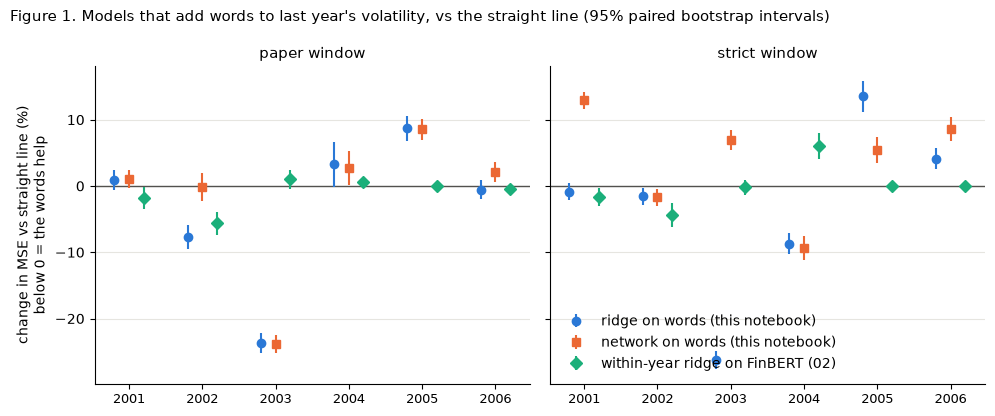

In [15]:
COLORS = {"ridge: words + last year": "#2a78d6", f"network: words + last year ({len(SEEDS)} seeds averaged)": "#eb6834",
          "within-year ridge, Item 7 (FinBERT, from 02)": "#1baf7a"}
MARKERS = dict(zip(COLORS, ["o", "s", "D"]))
OFFSET = dict(zip(COLORS, [-0.2, 0.0, 0.2]))
LABELS = {"ridge: words + last year": "ridge on words (this notebook)",
          f"network: words + last year ({len(SEEDS)} seeds averaged)": "network on words (this notebook)",
          "within-year ridge, Item 7 (FinBERT, from 02)": "within-year ridge on FinBERT (02)"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, window in zip(axes, scoring.WINDOWS):
    ax.axhline(0, color="#52514e", lw=1)
    for name in COLORS:
        r = shown[(shown.model == name) & (shown.window == window)]
        if r.empty:
            continue
        pct, lo, hi = r.change_pct, 100 * r.ci_low / r.baseline_mse, 100 * r.ci_high / r.baseline_mse
        ax.errorbar(r.test_year + OFFSET[name], pct, yerr=[pct - lo, hi - pct], fmt=MARKERS[name], color=COLORS[name],
                    ms=6, lw=1.5, capsize=0, label=LABELS[name])
    ax.set_title(f"{window} window", fontsize=11)
    ax.set_xticks(list(scoring.TEST_YEARS))
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("change in MSE vs straight line (%)\nbelow 0 = the words help")
axes[-1].legend(frameon=False, loc="best")
fig.suptitle("Figure 1. Models that add words to last year's volatility, vs the straight line (95% paired bootstrap intervals)",
             fontsize=11, x=0.01, ha="left")
fig.tight_layout()
plt.show()

**Level and spread.** In 02 the pooled ridge's gains and losses were almost all *level*: the text told it which year a report was from. Here is the same split for the models in this notebook (main window, change from the straight line in % of its MSE). If the network's gain is mostly level, it has learnt the year, not the company.

In [16]:
b_ = copy_vs_line[copy_vs_line.window == MAIN_WINDOW].set_index("test_year")
rows = {"line: level as % of its MSE": 100 * b_["baseline_level"] / b_["baseline_mse"]}
for name in ["ridge: words + last year", f"network: words + last year ({len(SEEDS)} seeds averaged)"]:
    r = results[(results.model == name) & (results.window == MAIN_WINDOW)].set_index("test_year")
    rows[f"{name}: change from the level"] = 100 * (r["level"] - r["baseline_level"]) / r["baseline_mse"]
    rows[f"{name}: change from the spread"] = 100 * (r["spread"] - r["baseline_spread"]) / r["baseline_mse"]
pd.DataFrame(rows).T.round(1)

test_year,2001,2002,2003,2004,2005,2006
line: level as % of its MSE,29.9,4.4,44.3,8.4,0.1,1.0
ridge: words + last year: change from the level,0.1,-4.4,-23.6,-6.0,4.9,0.3
ridge: words + last year: change from the spread,0.9,-3.3,-0.0,9.3,3.9,-0.9
network: words + last year (3 seeds averaged): change from the level,0.1,1.5,-23.8,-6.2,4.9,2.5
network: words + last year (3 seeds averaged): change from the spread,0.9,-1.6,-0.1,8.8,3.6,-0.4


In [18]:
def split_preds(window, T):
    train, test = (as_mask(m) for m in scoring.masks(df, T, window))
    p = dict(fit_split(train, test))
    a, b = scoring.fit_line(df, train)
    p["copy last year"], p["straight line"] = prev[test], a + b * prev[test]
    return y[test], p

rows = []
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        yt, p = split_preds(window, T)
        keep = yt >= VERY_LOW
        for name, pt in p.items():
            if "averaged" in name:
                continue
            rows.append({"window": window, "test_year": T, "model": name.split(", seed")[0], "test_mse": mse(yt, pt),
                         "test_mse_excl_takeovers": mse(yt[keep], pt[keep]), "takeover_share": 1 - keep.mean()})
tk = (pd.DataFrame(rows).groupby(["window", "model"], sort=False)
      .agg(test_mse=("test_mse", "mean"), test_mse_excl_takeovers=("test_mse_excl_takeovers", "mean"),
           reports_dropped=("takeover_share", lambda s: f"{s.mean():.1%}")))
tk.round(3)

test_mse  test_mse_excl_takeovers  \
window model                                                           
paper  train mean                     0.399                    0.381   
       ridge: words only              0.159                    0.144   
       ridge: words + last year       0.120                    0.106   
       network: words only            0.191                    0.176   
       network: words + last year     0.123                    0.109   
       copy last year                 0.124                    0.109   
       straight line                  0.127                    0.112   
strict train mean                     0.442                    0.423   
       ridge: words only              0.214                    0.197   
       ridge: words + last year       0.126                    0.111   
       network: words only            0.255                    0.238   
       network: words + last year     0.140                    0.125   
       copy last year                 0.124                    0.109   
       straight line                  0.133                    0.118   

                                  reports_dropped  
window model                                       
paper  train mean                            0.3%  
       ridge: words only                     0.3%  
       ridge: words + last year              0.3%  
       network: words only                   0.3%  
       network: words + last year            0.3%  
       copy last year                        0.3%  
       straight line                         0.3%  
strict train mean                            0.3%  
       ridge: words only                     0.3%  
       ridge: words + last year              0.3%  
       network: words only                   0.3%  
       network: words + last year            0.3%  
       copy last year                        0.3%  
       straight line                         0.3%

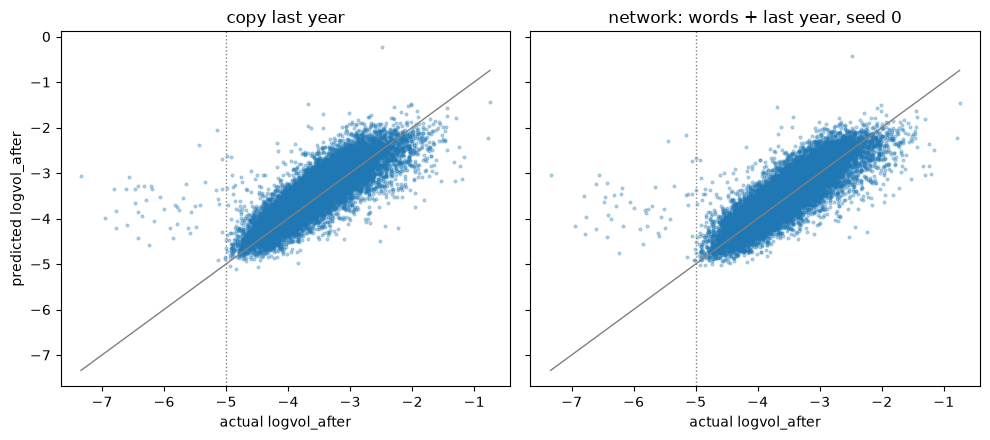

In [19]:
# Predicted against actual on all test years (main window): baseline on the left, network on the right
parts = [split_preds(MAIN_WINDOW, T) for T in scoring.TEST_YEARS]
yt = np.concatenate([p[0] for p in parts])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, name in zip(axes, ["copy last year", f"network: words + last year, seed {SEEDS[0]}"]):
    ax.scatter(yt, np.concatenate([p[1][name] for p in parts]), s=4, alpha=0.3)
    lims = [yt.min(), yt.max()]
    ax.plot(lims, lims, color="grey", lw=1)
    ax.axvline(VERY_LOW, color="grey", ls=":", lw=1)
    ax.set_xlabel("actual logvol_after")
    ax.set_title(name)
axes[0].set_ylabel("predicted logvol_after")
plt.tight_layout()
plt.show()

## 5.7 Interpretation and Findings


## Which words does it use?

Two views, both rough, for one fit: the last test year in the main window.

- **Ridge coefficients** (words only): each word's weight in a linear model. Positive means "higher volatility next year".
- **Gradient × input** for the network (words + last year): for each report, how much the prediction would change per unit change in a word's feature, multiplied by the feature value itself; averaged over test reports. Unlike ridge, the network can combine words, so this is a local approximation, not a weight.

In `04-Volatility-Checking.ipynb` we expected distress wording (bankruptcy, going concern) to push volatility up and takeover wording (merger, tender offer) to push it down. These are single words here, so only parts of those phrases appear.

In [20]:
T_LAST = max(scoring.TEST_YEARS)
M = MODELS[KEY_OF[(MAIN_WINDOW, T_LAST)]]
S_last = make_split(*scoring.masks(df, T_LAST, MAIN_WINDOW))      # features of this split again (also used in section 7)
assert (S_last.cols == M["cols"]).all(), "features were rebuilt differently from the fit"
words = vocab[M["cols"]]                            # the vocabulary this window chose on its training reports
word_index = {w: j for j, w in enumerate(words)}
print(f"window {MAIN_WINDOW}, test year {T_LAST}: train {KEY_OF[(MAIN_WINDOW, T_LAST)][0][0]}-{KEY_OF[(MAIN_WINDOW, T_LAST)][0][-1]}")

coef = M["ridge_text"].coef_
order_ = np.argsort(coef)
print("ridge, words only -- push volatility DOWN:", words[order_[:15]].tolist())
print("ridge, words only -- push volatility UP:  ", words[order_[::-1][:15]].tolist())

probe = ["merger", "tender", "acquisition", "bankruptcy", "chapter", "delisted", "default", "going", "concern"]
print("\nwords we expect to matter (ridge coefficient, log-volatility per unit of feature):")
print({w: round(float(coef[word_index[w]]), 3) for w in probe if w in word_index})

window paper, test year 2006: train 2001-2005
ridge, words only -- push volatility DOWN: ['sharebased', 'dividends', 'esop', 'unsecured', 'policies', 'regulated', 'ferc', 'acquisitions', 'repurchase', 'timing', 'warmer', 'largely', 'distributions', 'coal', 'acquire']
ridge, words only -- push volatility UP:   ['loss', 'nasdaq', 'doubt', 'concern', 'raise', 'financing', 'debenture', 'going', 'smallcap', 'extraordinary', 'reciprocal', 'longlived', 'managements', 'personnel', 'default']

words we expect to matter (ridge coefficient, log-volatility per unit of feature):
{'merger': -0.355, 'tender': -0.605, 'acquisition': -0.301, 'bankruptcy': -0.131, 'chapter': -0.214, 'delisted': 0.606, 'default': 0.751, 'going': 0.847, 'concern': 0.997}


In [21]:
model = M["net"]
model.eval()
rng = np.random.default_rng(0)
sample = rng.choice(S_last.te_idx, size=min(2000, len(S_last.te_idx)), replace=False)
attr = np.zeros(S_last.X.shape[1])
for i in range(0, len(sample), 500):
    r = sample[i:i + 500]
    xb = dense(S_last, r).requires_grad_(True)
    model(xb, torch.from_numpy(S_last.prev_z[r])).sum().backward()
    attr += (xb.grad * xb).sum(dim=0).detach().cpu().numpy()
attr /= len(sample)
order_ = np.argsort(attr)
print("network, words + last year -- push the prediction DOWN:", words[order_[:15]].tolist())
print("network, words + last year -- push the prediction UP:  ", words[order_[::-1][:15]].tolist())

network, words + last year -- push the prediction DOWN: ['contents', 'stockbased', 'billion', 'table', 'compensation', 'corrections', 'improved', 'returns', 'eitf', 'employee', 'disclosure', 'fin', 'interpretation', 'determining', 'settlement']
network, words + last year -- push the prediction UP:   ['longlived', 'impairment', 'supersedes', 'secured', 'term', 'preferred', 'obligations', 'financing', 'similar', 'loan', 'added', 'assets', 'line', 'payment', 'intangible']


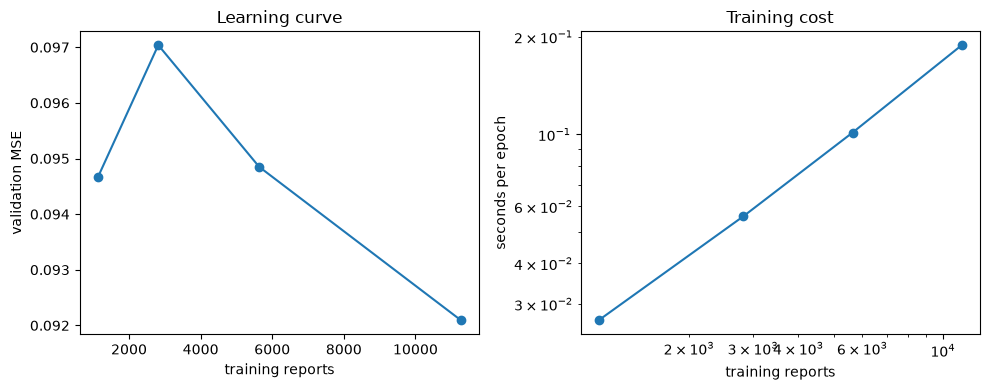

log-log slope of seconds per epoch against training reports: 0.85  (1.0 = cost grows in step with data)


,fraction,n_train,epochs,val_mse,sec_per_epoch,total_seconds
0,0.10,1127,6,0.095,0.027,0.396
1,0.25,2817,6,0.097,0.056,0.575
2,0.50,5635,10,0.095,0.101,1.399
3,1.00,11271,9,0.092,0.189,2.054


In [22]:
# Learning curve and training cost against training-set size (one seed each; words + last year network; main window, last test year)
rng = np.random.default_rng(0)
rows_ = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    sub = S_last.fit_idx if frac == 1.0 else rng.choice(S_last.fit_idx, size=int(frac * len(S_last.fit_idx)), replace=False)
    t0 = time.perf_counter()
    _, hist = train_nn(S_last, use_prev=True, seed=0, train_rows=sub)
    rows_.append({"fraction": frac, "n_train": len(sub), "epochs": len(hist), "val_mse": hist["val_mse"].min(),
                  "sec_per_epoch": hist["seconds"].mean(), "total_seconds": time.perf_counter() - t0})
lc = pd.DataFrame(rows_)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(lc["n_train"], lc["val_mse"], "o-")
axes[0].set_xlabel("training reports"); axes[0].set_ylabel("validation MSE"); axes[0].set_title("Learning curve")
axes[1].loglog(lc["n_train"], lc["sec_per_epoch"], "o-")
axes[1].set_xlabel("training reports"); axes[1].set_ylabel("seconds per epoch"); axes[1].set_title("Training cost")
plt.tight_layout()
plt.show()

slope_time = np.polyfit(np.log(lc["n_train"]), np.log(lc["sec_per_epoch"]), 1)[0]
print(f"log-log slope of seconds per epoch against training reports: {slope_time:.2f}  (1.0 = cost grows in step with data)")
lc.round(3)

## References
